In [24]:
import kagglehub
import numpy as np
import matplotlib
matplotlib.use('Agg')  # Ensure Agg backend is used
import matplotlib.pyplot as plt
plt.switch_backend('Agg')  # Switch backend if required
%matplotlib inline


import seaborn as sns
sns.set(style='whitegrid')


In [25]:
# Download latest version
path = kagglehub.dataset_download("hrosebaby/horse-racing-dataset-for-experts-hong-kong")

print("Path to dataset files:", path)

Path to dataset files: /home/kiit/.cache/kagglehub/datasets/hrosebaby/horse-racing-dataset-for-experts-hong-kong/versions/3


In [26]:
import pandas as pd
from pathlib import Path

In [27]:
path = "/home/kiit/.cache/kagglehub/datasets/hrosebaby/horse-racing-dataset-for-experts-hong-kong/versions/3"

folder = Path(path)

# List everything inside the folder
for item in folder.iterdir():
    print(item.name)

trackwork.csv
comments.csv
barrier.csv
results.csv
horse_info.csv


In [28]:
trackwork_df = pd.read_csv(folder / 'trackwork.csv')
comments_df = pd.read_csv(folder / 'comments.csv')
barrier_df = pd.read_csv(folder / 'barrier.csv')
results_df = pd.read_csv(folder / 'results.csv')
horse_info_df = pd.read_csv(folder / 'horse_info.csv')
trackwork_df.columns

Index(['Unnamed: 0', 'horse', 'horse_code', 'date', 'type', 'track',
       'workouts', 'gear'],
      dtype='str')

In [29]:
barrier_df.columns

Index(['Unnamed: 0', 'plc', 'horse', 'jockey', 'trainer', 'draw', 'gear',
       'lbw', 'runningpos', 'time', 'comment', 'date', 'distance', 'going',
       'raceno', 'venue', 'course', 'result', 'horse_ch', 'jockey_ch',
       'trainer_ch', 'result_ch', 'comment_ch', 'going_ch', 'venue_ch',
       'course_ch'],
      dtype='str')

In [30]:
results_df.columns

Index(['Unnamed: 0', 'row', 'plc', 'horseno', 'horse', 'jockey', 'trainer',
       'actualwt', 'declarwt', 'draw', 'lbw', 'runningpos', 'finishtime',
       'winodds', 'date', 'raceno', 'class', 'distance', 'going', 'handicap',
       'course', 'stake', 'venue', 'horse_ch', 'jockey_ch', 'trainer_ch',
       'class_ch', 'going_ch', 'handicap_ch', 'course_ch', 'venue_ch'],
      dtype='str')

In [31]:
horse_info_df.columns

Index(['Unnamed: 0', 'horse', 'country', 'trainer', 'colour', 'sex', 'owner',
       'import_type', 'current_rating', 'start_rating', 'sire', 'dam', 'age'],
      dtype='str')

In [32]:
results_df.shape

(14212, 31)

### Data Cleaning and Preprocessing
A quick inspection of the data reveals that several columns store dates as strings. In order to enable time series analysis or any date-based filtering in the future, we convert these columns to datetime types. For example, the results, trackwork, barrier, and comments datasets include a date column that we convert using pd.to_datetime. This step is particularly important to avoid errors or issues in later analysis stages, such as plotting time series graphs or resampling data.

In [33]:
def convert_date_columns(df, columns):
    for col in columns:
        if col in df.columns:
            try:
                df[col] = pd.to_datetime(df[col])
            except Exception as e:
                print(f'Error converting {col}:', e)
    return df

# Convert date columns where applicable
results_df = convert_date_columns(results_df, ['date'])
trackwork_df = convert_date_columns(trackwork_df, ['date'])
barrier_df = convert_date_columns(barrier_df, ['date'])
comments_df = convert_date_columns(comments_df, ['date'])

print('Date conversion complete. Sample dates:')
print(results_df['date'].head())

Date conversion complete. Sample dates:
0   2015-06-03
1   2015-06-07
2   2015-06-10
3   2015-06-14
4   2015-06-17
Name: date, dtype: datetime64[us]


In [34]:
results_df.drop(columns=["Unnamed: 0"], inplace=True)

In [35]:
horse_info_df.drop(columns=["Unnamed: 0"], inplace=True)

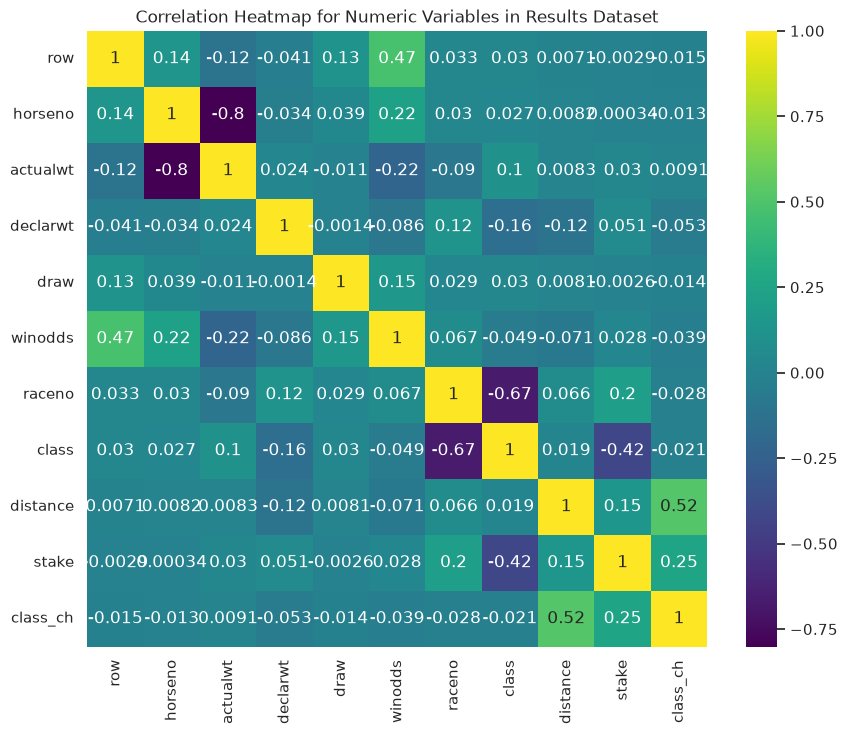

In [36]:
# Exploratory Data Analysis on numeric features in results_df
numeric_df = results_df.select_dtypes(include=[np.number])

if numeric_df.shape[1] >= 4:
    plt.figure(figsize=(10,8))
    sns.heatmap(numeric_df.corr(), annot=True, cmap='viridis')
    plt.title('Correlation Heatmap for Numeric Variables in Results Dataset')
    plt.show()

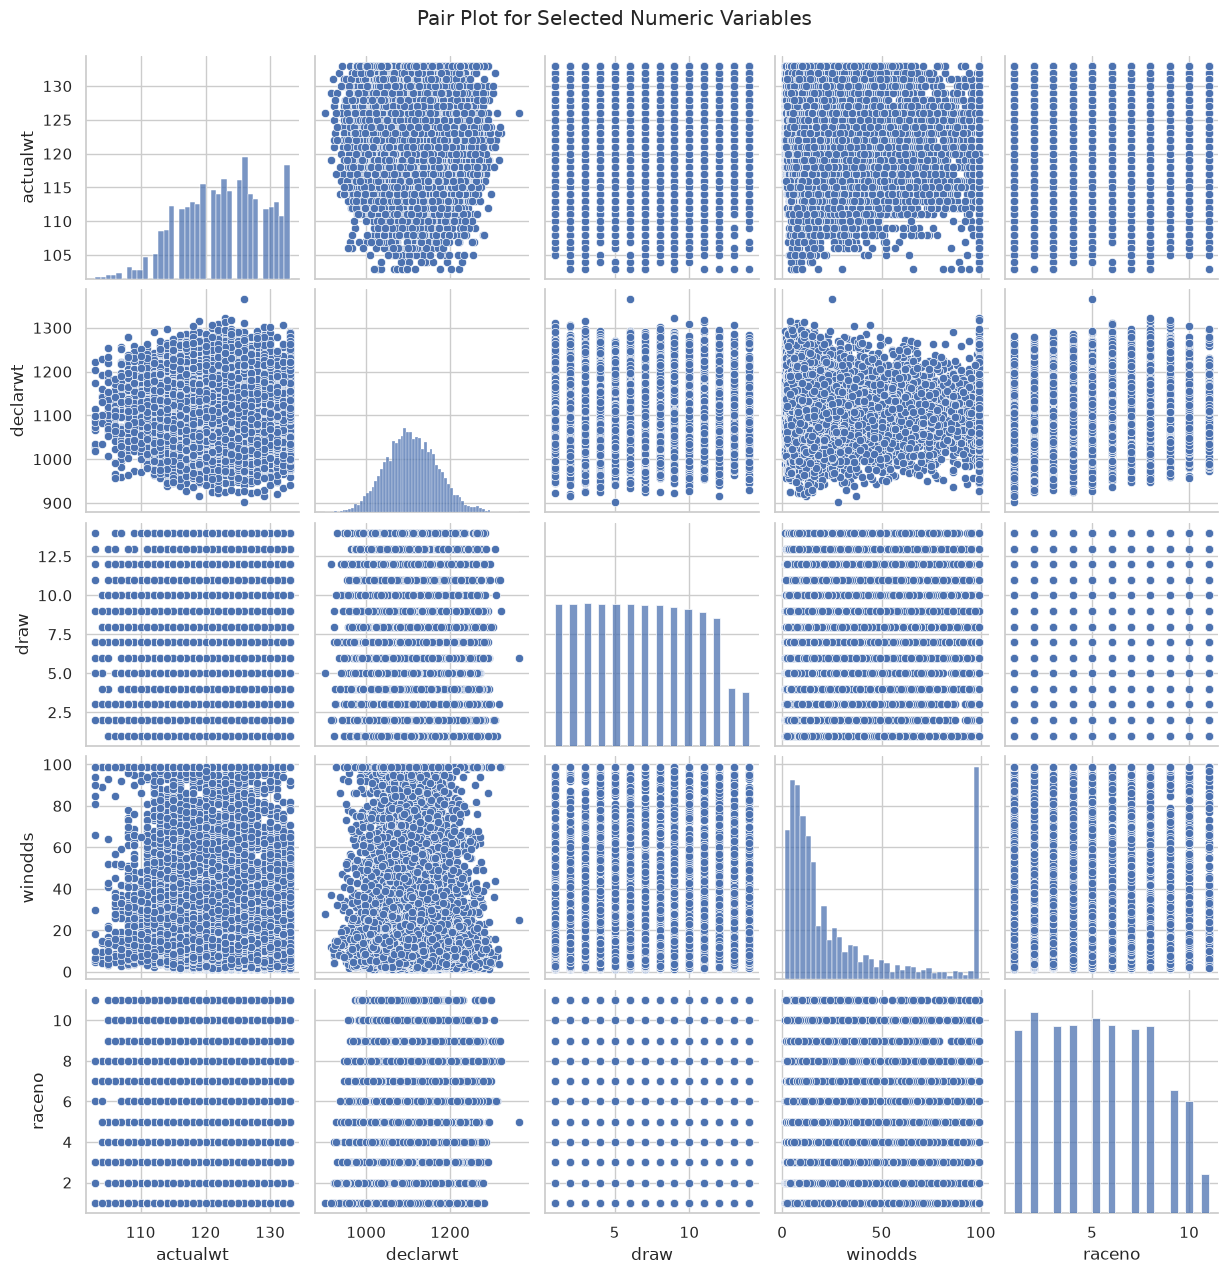

In [37]:
# Pair Plot for a subset of numerical features (if too many, select some columns)
selected_columns = ['actualwt', 'declarwt', 'draw', 'winodds', 'raceno']
if all(col in numeric_df.columns for col in selected_columns):
    sns.pairplot(results_df[selected_columns].dropna())
    plt.suptitle('Pair Plot for Selected Numeric Variables', y=1.02)
    plt.show()

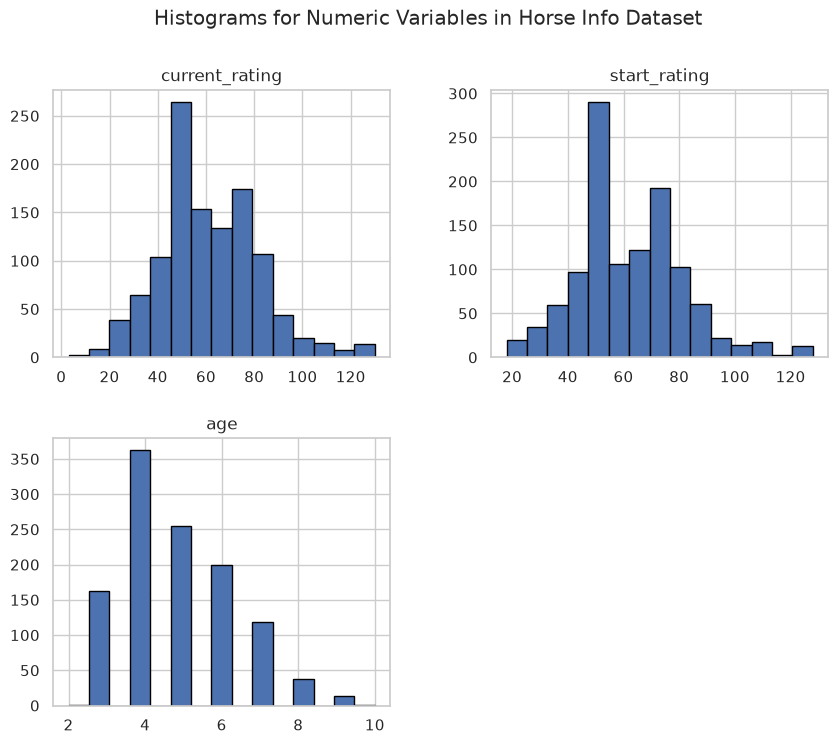

In [38]:
# Histogram of numeric columns in horse_info
numeric_horse = horse_info_df.select_dtypes(include=[np.number])
if not numeric_horse.empty:
    numeric_horse.hist(figsize=(10,8), bins=15, edgecolor='black')
    plt.suptitle('Histograms for Numeric Variables in Horse Info Dataset')
    plt.show()


In [ ]:
results_df.head(

,row,plc,horseno,horse,jockey,trainer,actualwt,declarwt,draw,lbw,...,stake,venue,horse_ch,jockey_ch,trainer_ch,class_ch,going_ch,handicap_ch,course_ch,venue_ch
0,0,1,10.0,NATURAL EIGHT(S243),C Y Ho,C Fownes,119.0,1037.0,1.0,-,...,575000,Happy Valley,威百利(S243),何澤堯,方嘉柏,1,好地至快地,畢拿山讓賽,草地 - A 賽道,跑馬地
1,0,1,7.0,SOLAR HEI HEI(T242),B Prebble,D J Hall,125.0,1077.0,11.0,-,...,760000,Sha Tin,太陽喜喜(T242),柏寶,賀賢,1,好地至快地,香港大學基金讓賽,草地 - A+3 賽道,沙田
2,0,1,3.0,GRAN BOLIVAR(S165),H N Wong,Y S Tsui,121.0,950.0,9.0,-,...,760000,Happy Valley,王將(S165),黃皓楠,徐雨石,1,好地至快地,麗安讓賽,草地 - B 賽道,跑馬地
3,0,1,11.0,PEOPLE'S KNIGHT(T305),G Mosse,J Moore,120.0,1149.0,4.0,-,...,800000,Sha Tin,人民武士(T305),巫斯義,約翰摩亞,1,好地至快地,ＢＲＥＧＵＥＴ平磅賽,草地 - B+2 賽道,沙田
4,0,1,2.0,SIR JOHN(P344),B Prebble,W Y So,131.0,1158.0,10.0,-,...,575000,Happy Valley,至尊駿爵(P344),柏寶,蘇偉賢,1,好地至快地,宏德讓賽,草地 - C 賽道,跑馬地
